In [1]:
#Importing all libraries to be used in this analysis 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from matplotlib.colors import ListedColormap
from sklearn.metrics import precision_score,recall_score,confusion_matrix,classification_report,accuracy_score,f1_score
from sklearn import metrics

import warnings
warnings.filterwarnings('ignore')



In [2]:
df = pd.read_csv(r"C:\Users\bindu\.cache\kagglehub\datasets\ratul\spam-mails-dataset\versions\1\spam_ham_dataset.csv")

In [3]:
df.drop(df.columns[0],axis=1,inplace=True)
df.drop(df.columns[-1],axis=1,inplace=True)

In [4]:
df.head()

,label,text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see..."
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar..."
3,spam,"Subject: photoshop , windows , office . cheap ..."
4,ham,Subject: re : indian springs\r\nthis deal is t...


In [5]:
df = df.rename(columns={"label":"Target","text":"Text"})

In [6]:
df.head()

,Target,Text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see..."
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar..."
3,spam,"Subject: photoshop , windows , office . cheap ..."
4,ham,Subject: re : indian springs\r\nthis deal is t...


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Target  5171 non-null   object
 1   Text    5171 non-null   object
dtypes: object(2)
memory usage: 80.9+ KB


Text(0, 0.5, 'Count of Messages')

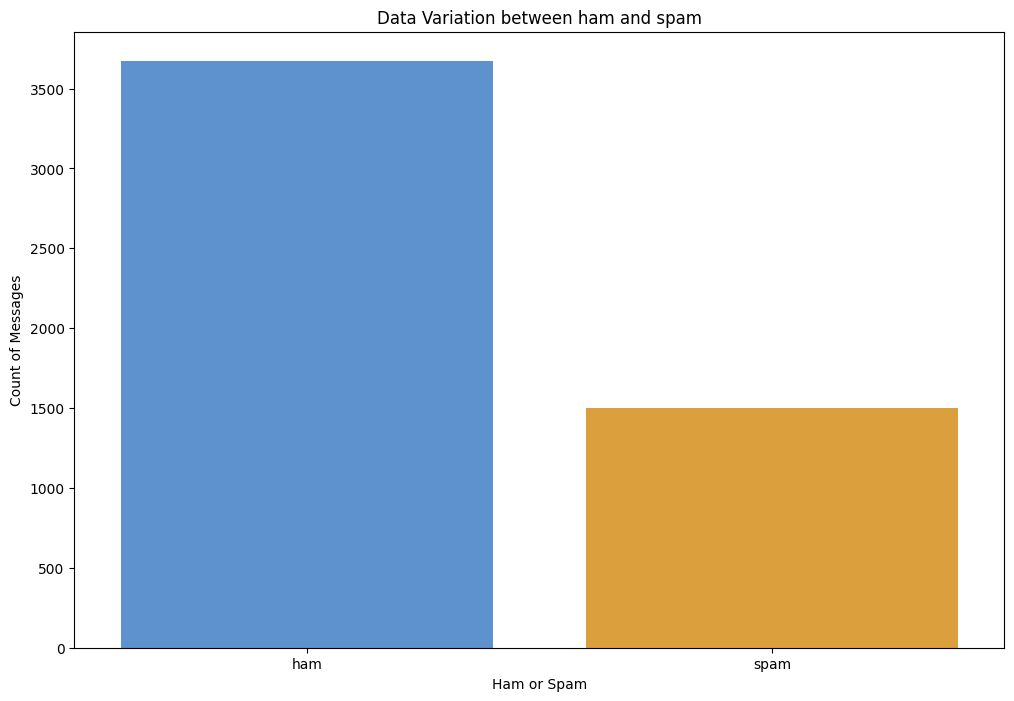

In [8]:
plt.figure(figsize=(12,8))
fg = sns.countplot(data=df, x= df["Target"],hue="Target",palette= ["#4A90E2", "#F5A623"])
fg.set_title("Data Variation between ham and spam")
fg.set_xlabel("Ham or Spam")
fg.set_ylabel("Count of Messages")

1. The data seems to have imbalances

### Since data seeems to be all in the text column let us make some derived columns

In [9]:
df["Num_of_Char"] = df["Text"].apply(len)
df["Nu_of_Words"] = df["Text"].apply(lambda text: len(nltk.word_tokenize(text)))
df["Nu_of_Sentences"] = df["Text"].apply(lambda text: len(nltk.sent_tokenize(text)))

In [10]:
df.head()

,Target,Text,Num_of_Char,Nu_of_Words,Nu_of_Sentences
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,327,68,3
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",97,24,3
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",2524,551,24
3,spam,"Subject: photoshop , windows , office . cheap ...",414,49,3
4,ham,Subject: re : indian springs\r\nthis deal is t...,336,71,3


In [11]:
df.describe()

,Num_of_Char,Nu_of_Words,Nu_of_Sentences
count,5171.000000,5171.000000,5171.000000
mean,1048.391994,229.181009,13.121253
std,1528.513435,336.487397,27.541637
min,11.000000,2.000000,1.000000
25%,244.000000,52.000000,4.000000
50%,540.000000,122.000000,7.000000
75%,1237.000000,283.500000,15.000000
max,32258.000000,8863.000000,1204.000000


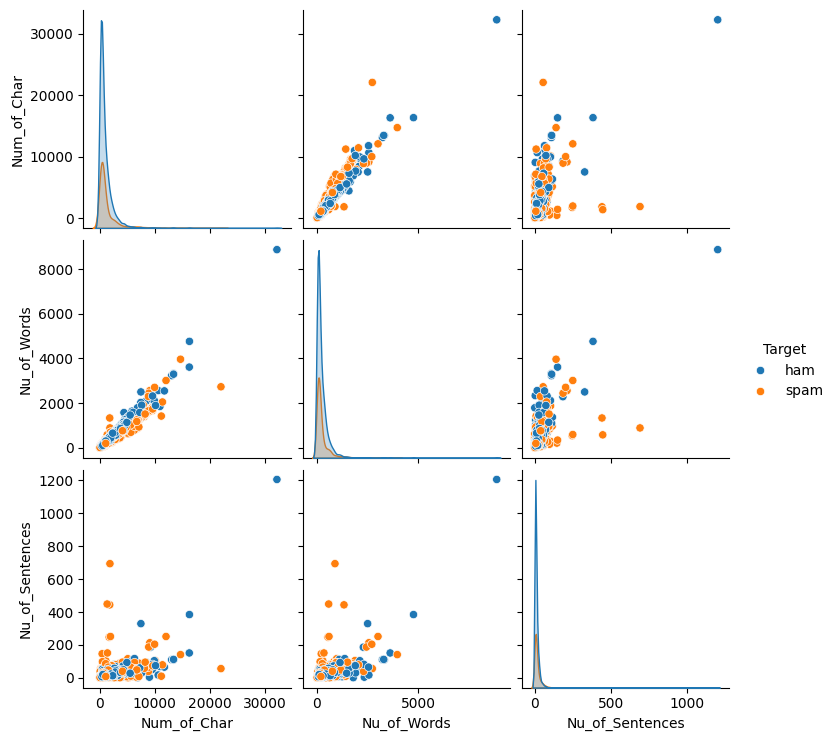

In [12]:
fg = sns.pairplot(data = df,hue = 'Target')

In [13]:
df.columns

Index(['Target', 'Text', 'Num_of_Char', 'Nu_of_Words', 'Nu_of_Sentences'], dtype='object')

In [14]:
# List of target columns
cols = ['Num_of_Char', 'Nu_of_Words', 'Nu_of_Sentences']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter the DataFrame to keep only non-outliers
    df_clean = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]


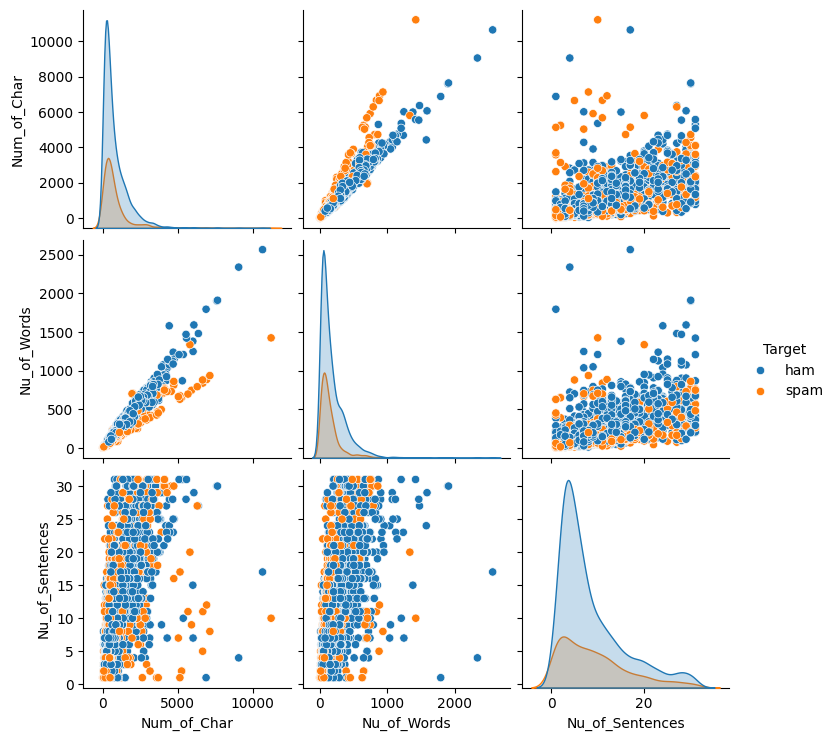

In [15]:
fg = sns.pairplot(data=df_clean,hue = 'Target')

In [16]:
print(df_clean.loc[0:5,"Text"],sep= "\n")

0    Subject: enron methanol ; meter # : 988291\r\n...
1    Subject: hpl nom for january 9 , 2001\r\n( see...
2    Subject: neon retreat\r\nho ho ho , we ' re ar...
3    Subject: photoshop , windows , office . cheap ...
4    Subject: re : indian springs\r\nthis deal is t...
5    Subject: ehronline web address change\r\nthis ...
Name: Text, dtype: object


### Let us clean the text before preprocessing

In [17]:
def Clean(Text):
    #regex to replace all non-alpha char with blank
    email = re.sub('[^a-zA-Z]'," ",Text)
    email = email.lower()
    email = email.split()
    email = " ".join(email)
    return email

df_clean["Clean_Text"] = df_clean["Text"].apply(Clean)

In [18]:
df_clean.head()

,Target,Text,Num_of_Char,Nu_of_Words,Nu_of_Sentences,Clean_Text
0,ham,Subject: enron methanol ; meter # : 988291\r\n...,327,68,3,subject enron methanol meter this is a follow ...
1,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",97,24,3,subject hpl nom for january see attached file ...
2,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",2524,551,24,subject neon retreat ho ho ho we re around to ...
3,spam,"Subject: photoshop , windows , office . cheap ...",414,49,3,subject photoshop windows office cheap main tr...
4,ham,Subject: re : indian springs\r\nthis deal is t...,336,71,3,subject re indian springs this deal is to book...


## Tokenizing the data to smaller chunks

In [19]:
df_clean["Tokenized_data"] = df_clean.apply(lambda row: nltk.word_tokenize(row["Clean_Text"]),axis= 1)

In [20]:
df_clean["Tokenized_data"].head()

0    [subject, enron, methanol, meter, this, is, a,...
1    [subject, hpl, nom, for, january, see, attache...
2    [subject, neon, retreat, ho, ho, ho, we, re, a...
3    [subject, photoshop, windows, office, cheap, m...
4    [subject, re, indian, springs, this, deal, is,...
Name: Tokenized_data, dtype: object

In [21]:
from nltk.corpus import stopwords
import nltk

def remove_stopwords(text):
    stop_words = set(stopwords.words("english"))
    filtered_text = [x for x in text if x not in stop_words]
    return filtered_text


df_clean["Stop_word_rem"] = df_clean["Tokenized_data"].apply(remove_stopwords)

In [22]:
df_clean["Stop_word_rem"].head()

0    [subject, enron, methanol, meter, follow, note...
1    [subject, hpl, nom, january, see, attached, fi...
2    [subject, neon, retreat, ho, ho, ho, around, w...
3    [subject, photoshop, windows, office, cheap, m...
4    [subject, indian, springs, deal, book, teco, p...
Name: Stop_word_rem, dtype: object

### Moving onto lemmatization

In [23]:
lemmatizer  = WordNetLemmatizer()
def word_lemmatizer(word):
    lemmas = [lemmatizer.lemmatize(x,pos = "v") for x in word]
    return lemmas

df_clean["Lemmatized_Text"] = df_clean["Stop_word_rem"].apply(word_lemmatizer)

In [24]:
df_clean[["Stop_word_rem", "Lemmatized_Text"]].head()


,Stop_word_rem,Lemmatized_Text
0,"[subject, enron, methanol, meter, follow, note...","[subject, enron, methanol, meter, follow, note..."
1,"[subject, hpl, nom, january, see, attached, fi...","[subject, hpl, nom, january, see, attach, file..."
2,"[subject, neon, retreat, ho, ho, ho, around, w...","[subject, neon, retreat, ho, ho, ho, around, w..."
3,"[subject, photoshop, windows, office, cheap, m...","[subject, photoshop, windows, office, cheap, m..."
4,"[subject, indian, springs, deal, book, teco, p...","[subject, indian, spring, deal, book, teco, pv..."


In [25]:
#Create acorpus of text for training data
corpus = []
for i in df_clean["Lemmatized_Text"]:
    msg = ''.join([x for x in i])
    corpus.append(msg)
print("The output of the corpus :\033[0m",*corpus[:5], sep = "\n")

The output of the corpus :
subjectenronmethanolmeterfollownotegivemondaypreliminaryflowdataprovidedarenpleaseoverridepopdailyvolumepresentlyzeroreflectdailyactivityobtaingascontrolchangeneedasapeconomicspurpose
subjecthplnomjanuaryseeattachfilehplnolxlshplnolxls
subjectneonretreathohohoaroundwonderfultimeyearneonleadersretreattimeknowtimeyearextremelyhectictoughthinkanythingpastholidaylifegopastweekdecemberjanuarylikethinkminutecalenderhandbeginfallsemesterretreatscheduleweekendjanuaryyouthministerconferencebraddustinconnectweekgochangedatefollowweekendjanuarycomepartneedthinkthinkagreeimportantusgettogethertimerechargebatteriesgetfarspringsemesterlottroubledifficultusgetawaywithoutkidetcbradcomepotentialalternativegettogetherweekendletknowpreferfirstoptionwouldretreatsimilardopastseveralyearsyearcouldgoheartlandcountryinnwwwcomoutsidebrenhamniceplacebedroombedroomhousesidesidecountryrealrelaxalsoclosebrenhamonehourminutesgolfshopantiquecraftstorebrenhameatdinnertogetherranchspendtimem

In [26]:
tfidv = TfidfVectorizer()
X = tfidv.fit_transform(corpus).toarray()
X.dtype

dtype('float64')

In [27]:
# Labelling the target for the model
label_encoder = LabelEncoder()
df["Target"] = label_encoder.fit_transform(df["Target"])

### Model Training

In [28]:
y = df_clean['Target']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [29]:
classifiers = [MultinomialNB(),RandomForestClassifier(),KNeighborsClassifier(),SVC()]

In [30]:
for models in classifiers:
    models.fit(X_train,y_train)

In [31]:
# model dictionary for reference going forward
pipe_dict = {0: "NaiveBayes", 1: "RandomForest", 2: "KNeighbours",3: "SVC"}

In [32]:
for i,model in enumerate(classifiers):
    cv_score = cross_val_score(model,X_train,y_train,scoring="accuracy",cv=10)
    print(pipe_dict[i],cv_score.mean())

NaiveBayes 0.7302451048465491
RandomForest 0.7376211637272602
KNeighbours 0.6918247465629774
SVC 0.7376211637272602


In [ ]:
# Model Evaluation
# creating lists of varios scores
precision =[]
recall =[]
f1_score = []
trainset_accuracy = []
testset_accuracy = []

for i in classifiers:
    pred_train = i.predict(X_train)
    pred_test = i.predict(X_test)
    prec = metrics.precision_score(y_test, pred_test, pos_label="spam")
    recal = metrics.recall_score(y_test, pred_test, pos_label="spam")
    f1_s = metrics.f1_score(y_test, pred_test, pos_label="spam")
    train_accuracy = model.score(X_train,y_train)
    test_accuracy = model.score(X_test,y_test)
  
    #Appending scores
    precision.append(prec)
    recall.append(recal)
    f1_score.append(f1_s)
    trainset_accuracy.append(train_accuracy)
    testset_accuracy.append(test_accuracy)

In [ ]:
# initialise data of lists.
data = {'Precision':precision,
'Recall':recall,
'F1score':f1_score,
'Accuracy on Testset':testset_accuracy,
'Accuracy on Trainset':trainset_accuracy}
# Creates pandas DataFrame.
Results = pd.DataFrame(data, index =["NaiveBayes", "RandomForest", "KNeighbours","SVC"])

In [ ]:
cmap2 = ListedColormap(["#E2CCFF","#E598D8"])
Results.style.background_gradient(cmap=cmap2)

In [ ]:
best_accuracy = Results["Accuracy on Testset"].idxmax()
acc_num_max = round(float(Results.loc["NaiveBayes", "Accuracy on Testset"]), 2)


In [ ]:
print("Best model based on Test Accuracy:", best_accuracy,acc_num_max)